#Install packages and environment

In [ ]:
!pip install linearmodels
import requests
import pandas as pd
import numpy as np
import plotly.express as px
import statsmodels
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
import plotly.io as pio
pio.renderers.default = "colab"
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline
from scipy.optimize import curve_fit
import plotly.graph_objects as go
from linearmodels.panel import PanelOLS
import warnings
import geopandas as gpd
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.patches as patches
import seaborn as sns

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 25.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 4.8 MB/s eta 0:00:00


#**Burning From Within: Heat Waves and the Rise of Domestic Violence**

Every 24 hours, over 28,000 individuals across the United States experience rape, physical violence, or stalking at the hands of an intimate partner (Black et al., 2011). This staggering figure translates to more than 12 million victims annually, making domestic violence one of the most pervasive public health crises of our time. Beyond the immediate physical harm, intimate partner violence reverberates through entire communities—affecting workplace productivity, straining healthcare systems, and perpetuating cycles of trauma across generations. The lifetime economic burden of intimate partner violence reaches an estimated $3.6 trillion, a figure that captures only a fraction of the human suffering behind these statistics (Peterson et al., 2018). As societies worldwide grapple with this enduring crisis, understanding the environmental and social factors that exacerbate domestic violence becomes increasingly critical.

Los Angeles, a sprawling metropolis of nearly four million people (U.S. Census Bureau, 2024), sits at the intersection of two converging crises: domestic violence and climate change. In recent years, the city has witnessed the devastating consequences of a warming planet. In summer 2024, a record-breaking heat wave struck Southern California, followed by an unprecedented dry season that left the region with just 0.16 inches of rain between May and December 2024—the second-driest period in recorded history (KTLA, 2024). This climatic whiplash—alternating between extreme wet and dry conditions—has transformed Los Angeles into a tinderbox. The January 2025 Palisades and Eaton wildfires consumed over 50,000 acres, killed 29 people, and destroyed more than 16,000 structures, marking one of the most destructive wildfire episodes in the region's history (Britannica, 2025; NBC News, 2025). These disasters are not isolated incidents but symptoms of a broader environmental transformation. 2024 was confirmed as the hottest year on record, with global temperatures reaching 1.28°C above the 20th-century baseline (NASA, 2025; NOAA, 2025), fundamentally altering the rhythms of life in California and beyond.

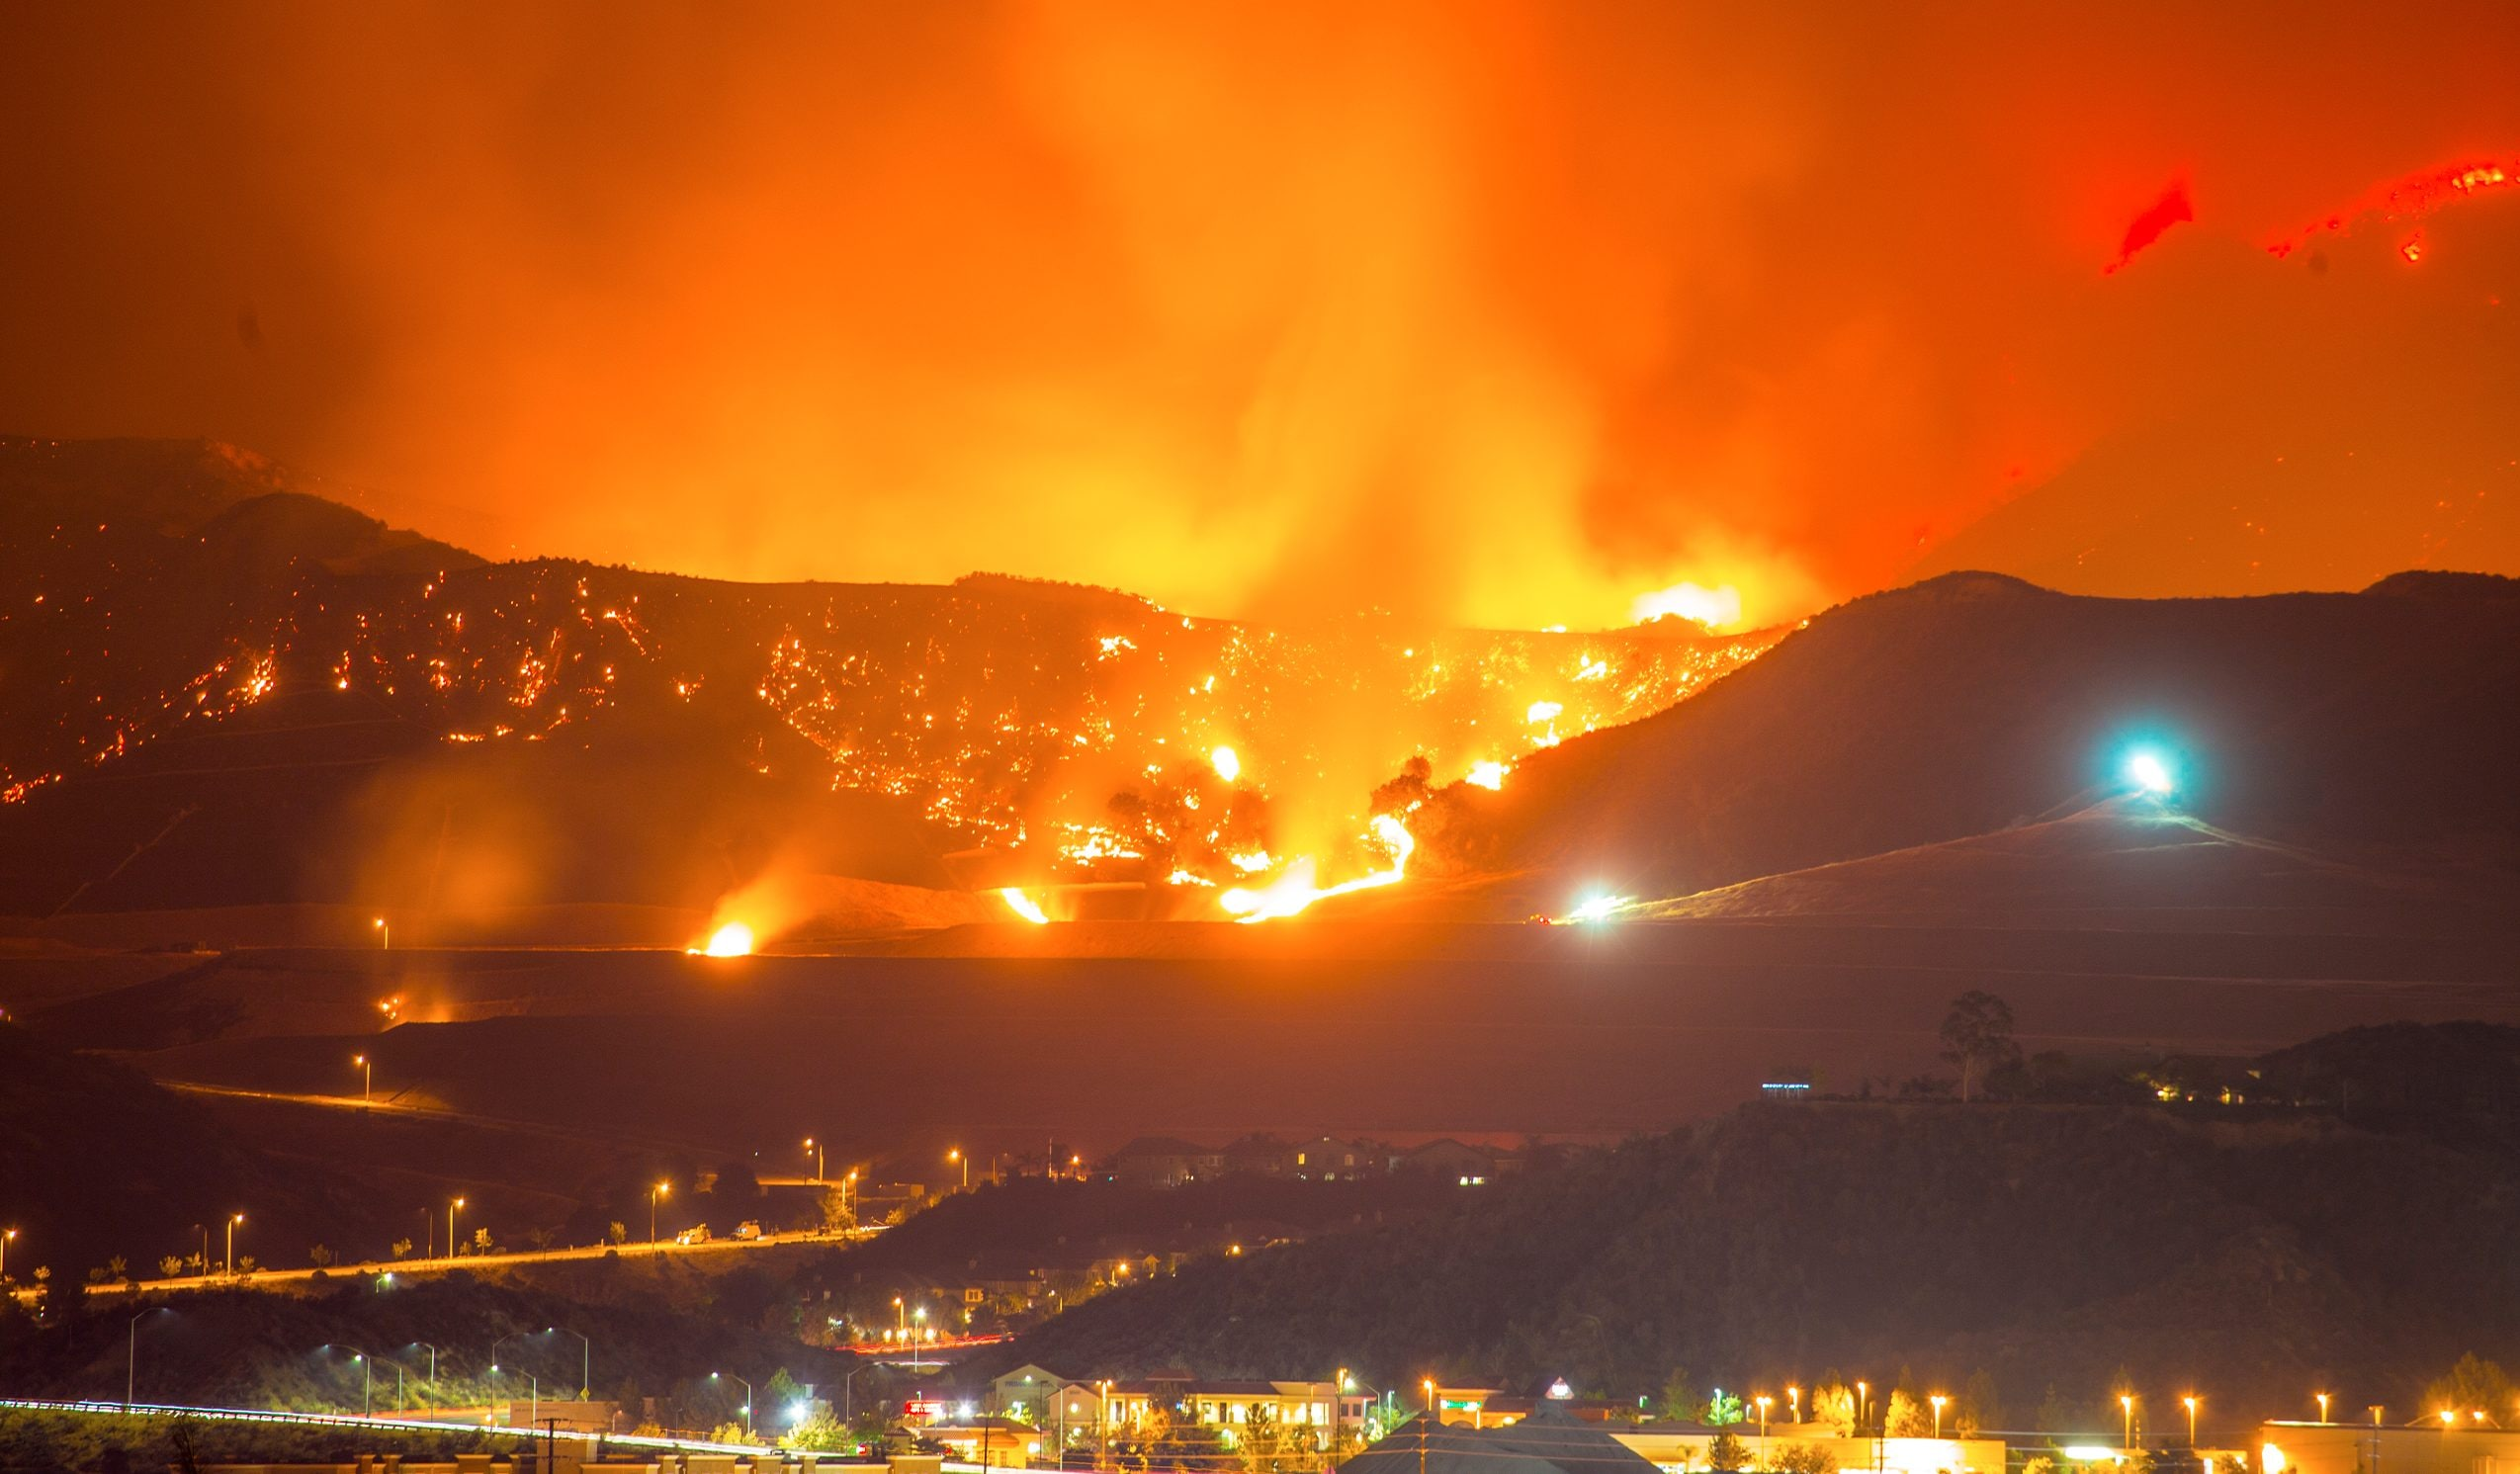

Fire hazard in Los Angeles, 2025

Yet the impacts of climate change extend far beyond visible destruction. A growing body of research reveals a more insidious consequence: rising temperatures directly influence human behavior, particularly aggression and violence (Anderson, 1989, 2001; Hsiang et al., 2013). When people experience uncomfortably hot conditions, their irritability, hostile thinking, and likelihood of physical aggression increase. This phenomenon, known as the heat-aggression hypothesis, has been documented across laboratory experiments, geographic comparisons, and time-series analyses (Anderson et al., 2000). Hot temperatures elevate aggressive behaviors both by directly increasing hostile feelings and indirectly by triggering aggressive thoughts. The physiological mechanism is straightforward: extreme heat forces the brain to divert resources toward cooling the body, reducing capacity for emotional regulation and impulse control. At a population level, researchers estimate that for each one standard deviation increase toward warmer temperatures, interpersonal violence increases by approximately 4% and intergroup conflict by 14% (Hsiang et al., 2013). In the United States specifically, if average annual temperatures increase by 8°F, violent crime rates could rise substantially, translating to over 100,000 additional serious assaults annually (Anderson, 2001)

This connection between temperature and aggression raises a troubling question: as Los Angeles experiences more frequent and intense heat waves, what happens to domestic violence within the city's homes? Using data from the Los Angeles Police Department's domestic violence calls database covering incidents from 2020 to present (City of Los Angeles, 2024), this analysis investigates whether heat waves correlate with increases in reported domestic violence incidents. By examining temperature patterns alongside documented domestic violence calls, we aim to uncover whether climate change is not only burning California's landscapes but also intensifying violence behind closed doors. Understanding this relationship is essential for developing targeted interventions that can protect vulnerable populations during periods of extreme heat—and for recognizing the full spectrum of climate change's human costs.

#To conduct our study, here is how we designed our causal map

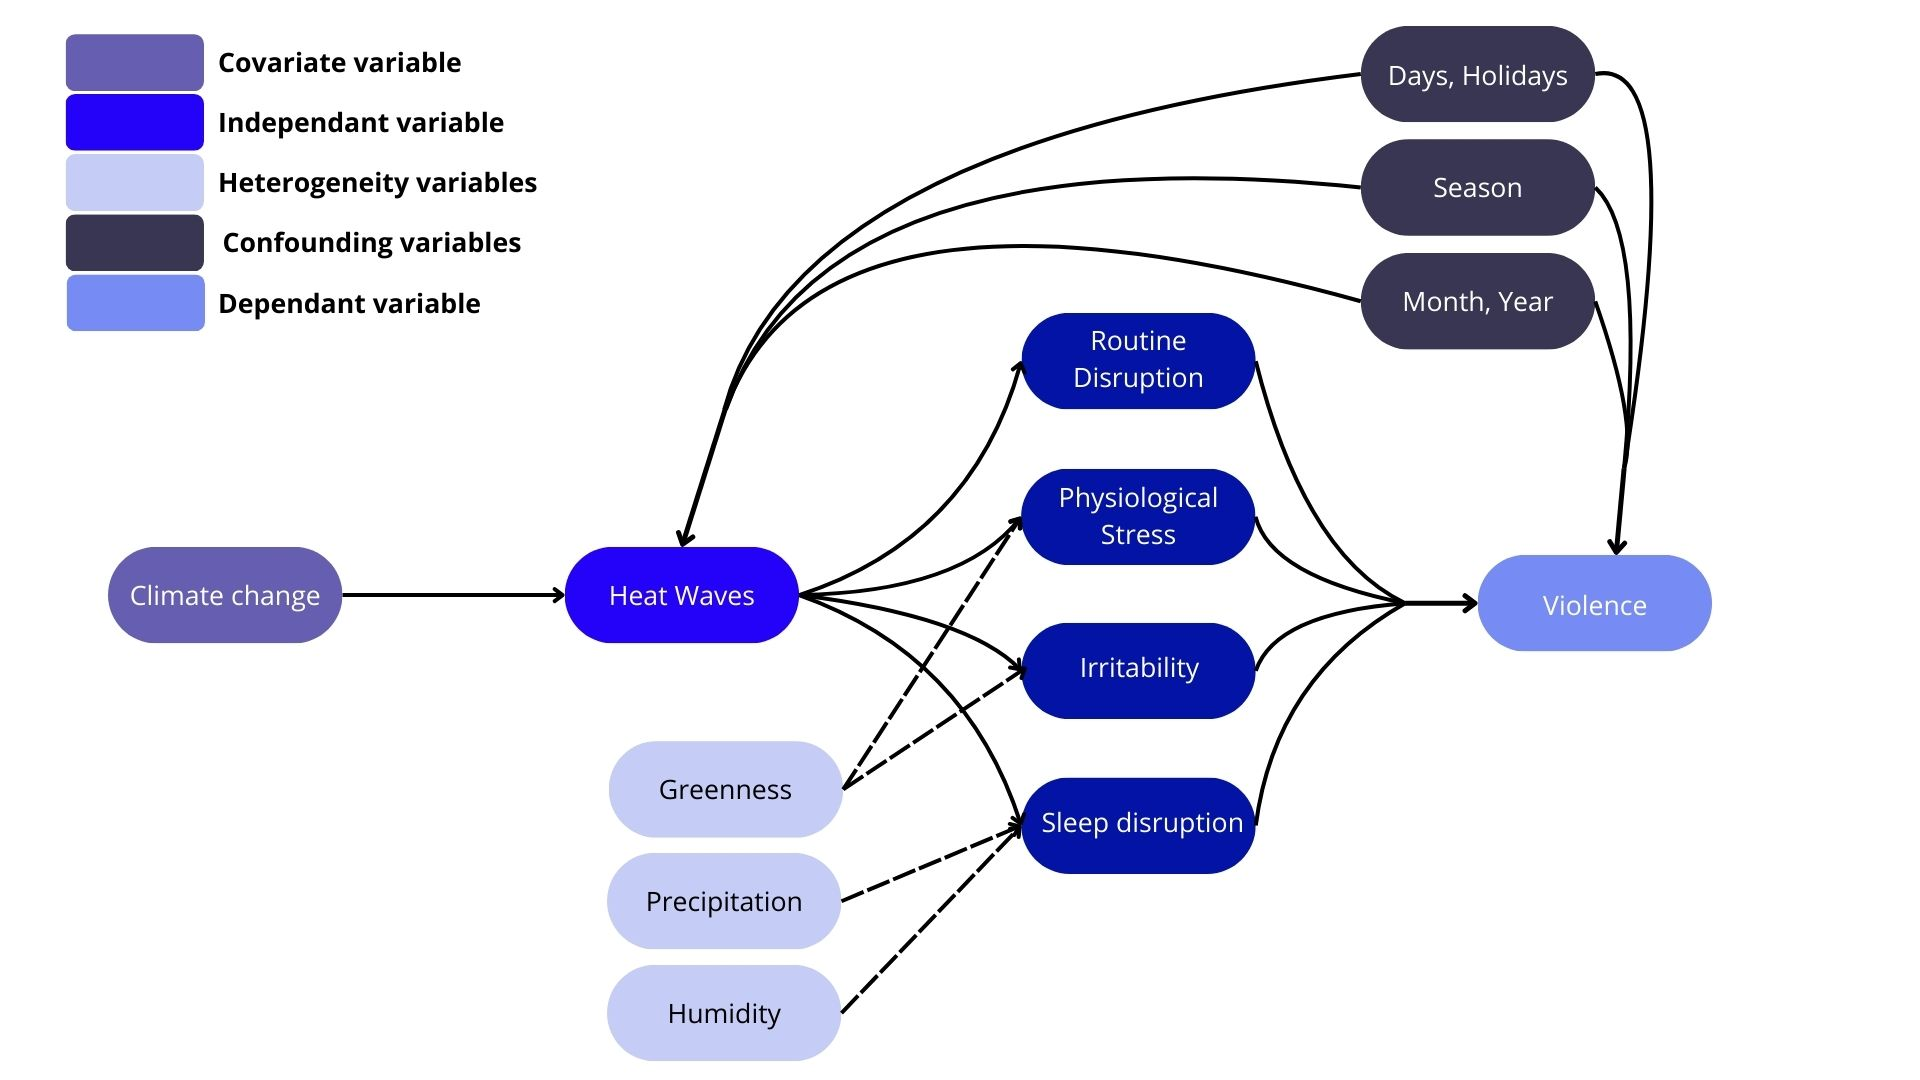

#What is the data we need ?

In [ ]:
url = "https://raw.githubusercontent.com/Mergim1110/Tiger_MGMT_499/refs/heads/main/data/final_panel.csv"
df = pd.read_csv(url, sep=",")
display(df.head(5))

,district_id,date,year,month,dow,holiday,crime_count,crime_rate,population,temp_max,...,hot_day_30,hot_day_35,hot_day_38,heatwave_30_3d,heatwave_35_3d,heatwave_30_5d,heatwave_35_5d,heatwave_38_3d,greenness,green
0,1,2020-01-01,2020,1,Wednesday,1,3.0,3.788979,79177.0,17.5,...,0,0,0,0,0,0,0,0,0.129273,0
1,1,2020-01-02,2020,1,Thursday,0,3.0,3.788979,79177.0,16.8,...,0,0,0,0,0,0,0,0,0.129273,0
2,1,2020-01-03,2020,1,Friday,0,2.0,2.525986,79177.0,20.6,...,0,0,0,0,0,0,0,0,0.129273,0
3,1,2020-01-04,2020,1,Saturday,0,1.0,1.262993,79177.0,18.6,...,0,0,0,0,0,0,0,0,0.129273,0
4,1,2020-01-05,2020,1,Sunday,0,1.0,1.262993,79177.0,19.7,...,0,0,0,0,0,0,0,0,0.129273,0


#Let's embark in this journey with us

## We begin with the simplest possible specification to illustrate why naive correlations can be misleading.

$$\text{Crime Rate}_{it} = \beta_0 + \beta_1 \text{Heatwave}_{it} + \epsilon_{it}$$

Where:
- $\text{Crime Rate}_{it}$ = (Number of domestic violence incidents recorded in district $i$ on day $t$ / $\text{Population}_{i}$) × 100,000
- $\text{Heatwave}_{it}$ = Binary indicator for 3 consecutive days with max temperature ≥30°C

In [ ]:
# Simple OLS regression
X = df[['heatwave_30_3d']]
X = sm.add_constant(X)
y = df['crime_rate']

model = sm.OLS(y, X)
results = model.fit()

print(results.summary())

                            OLS Regression Results                            
Dep. Variable:             crime_rate   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                     1.289
Date:                Fri, 19 Dec 2025   Prob (F-statistic):              0.256
Time:                        14:59:01   Log-Likelihood:                -48156.
No. Observations:               30681   AIC:                         9.632e+04
Df Residuals:                   30679   BIC:                         9.633e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              1.3170      0.007    184.

We begin with a simple, pooled regression that ignores where and when observations occur. In this specification, heatwave exposure shows no statistically significant association with domestic violence (p = 0.26).

Rather than revealing an effect, this result tells us something more important: the naive model is uninformative. By treating all districts and all days as comparable, it washes out meaningful variation and mixes fundamentally different places together. In a city as heterogeneous as Los Angeles, such an approach cannot distinguish short-run heat effects from persistent differences across neighborhoods.

In other words, the absence of a detectable relationship is not evidence that heat does not matter—it is evidence that we need a more careful empirical strategy.

To see what this heterogeneity looks like in practice, let's look at the spatial distribution of heat exposure and domestic violence across Los Angeles

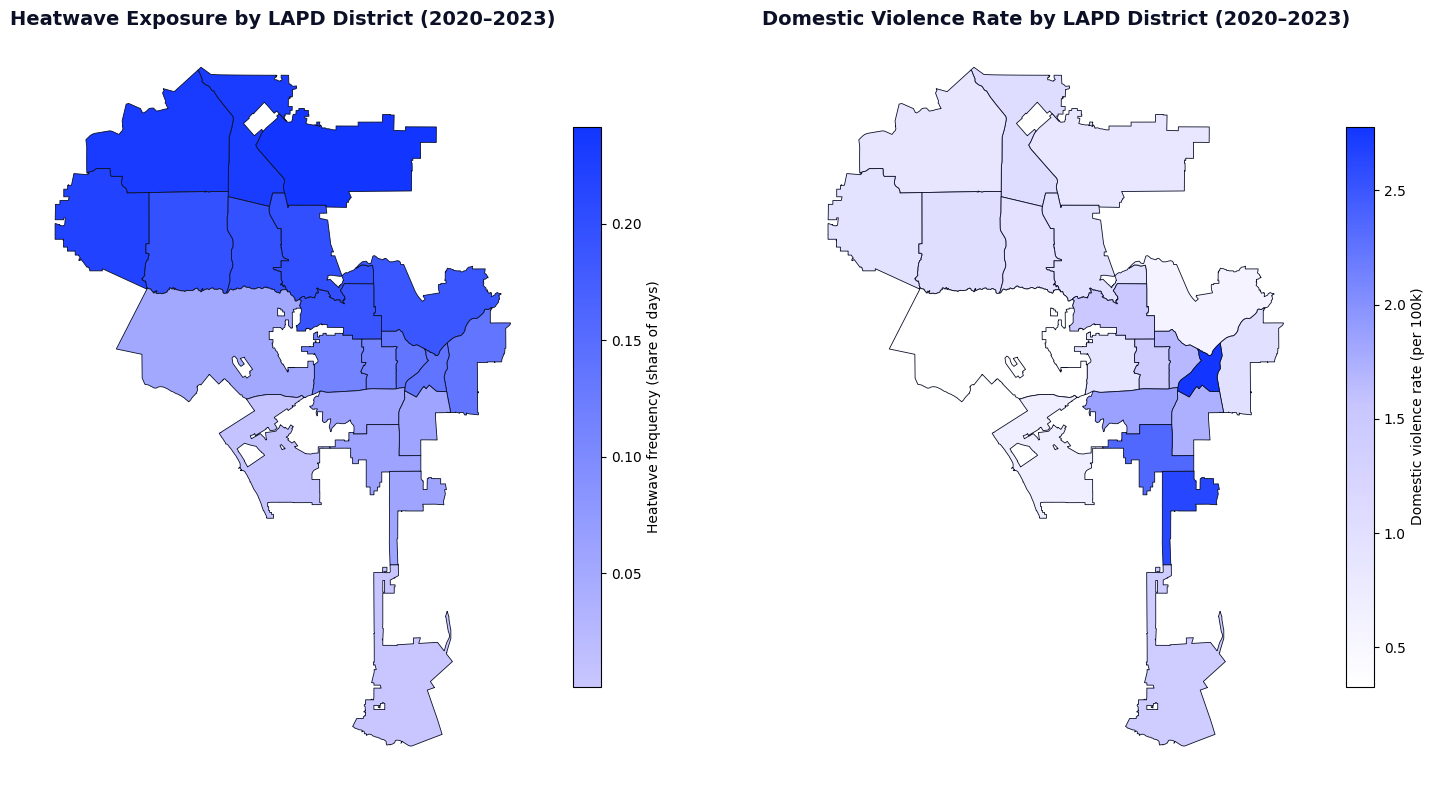

In [ ]:
# Color palette
BLUE = "#1236FF"      # deep blue
LAV  = "#C9C6FF"      # lavender
DARK = "#0B1026"      # almost-black
GRID = "#D7D9E8"      # light grid / frame

# Heatwave: lavender -> blue
cmap_heat = LinearSegmentedColormap.from_list("LavBlue", [LAV, BLUE])

# Crime: white -> lavender -> blue  (starts from white)
cmap_crime = LinearSegmentedColormap.from_list("WhiteLavBlue", ["#FFFFFF", LAV, BLUE])


# Load shapefile (GeoJSON)
url = "https://raw.githubusercontent.com/Mergim1110/Tiger_MGMT_499/refs/heads/main/data/LAPD_Divisions.geojson"
districts_gdf = gpd.read_file(url)


# Build district-level averages

district_summary = (
    df.groupby("district_id", as_index=False)
      .agg(heatwave_30_3d=("heatwave_30_3d", "mean"),
           crime_rate=("crime_rate", "mean"))
)

# PREC is district id in the geojson
districts_gdf["district_id"] = districts_gdf["PREC"].astype(int)

# Merge
districts_gdf = districts_gdf.merge(district_summary, on="district_id", how="left")


# Plot maps
fig, axes = plt.subplots(1, 2, figsize=(16, 8), facecolor="white")

# Map 1: Heatwave exposure
districts_gdf.plot(
    column="heatwave_30_3d",
    ax=axes[0],
    cmap=cmap_heat,
    legend=True,
    edgecolor=DARK,
    linewidth=0.6,
    legend_kwds={"label": "Heatwave frequency (share of days)", "shrink": 0.75}
)
axes[0].set_title("Heatwave Exposure by LAPD District (2020–2023)",
                  fontsize=14, fontweight="bold", color=DARK)
axes[0].axis("off")

# Map 2: Crime rate (starts from white)
districts_gdf.plot(
    column="crime_rate",
    ax=axes[1],
    cmap=cmap_crime,
    legend=True,
    edgecolor=DARK,
    linewidth=0.6,
    legend_kwds={"label": "Domestic violence rate (per 100k)", "shrink": 0.75}
)
axes[1].set_title("Domestic Violence Rate by LAPD District (2020–2023)",
                  fontsize=14, fontweight="bold", color=DARK)
axes[1].axis("off")

# Add a subtle frame around each map, pretty cool
for ax in axes:
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.2)
        spine.set_edgecolor(GRID)

plt.tight_layout()
plt.savefig("la_districts_maps_styled.png", dpi=300, bbox_inches="tight")
plt.show()


# Understanding the Paradox

At first glance, the maps may even suggest that districts with greater heat exposure tend to have lower average levels of domestic violence.

However, this pattern reflects persistent differences across neighborhoods rather than the causal effect of heat. Districts that experience more frequent heatwaves are not simply hotter—they are systematically different places, with distinct demographic, economic, and housing characteristics. These baseline differences shape both exposure to heat and underlying levels of violence. Any apparent relationship in the maps therefore reflects where heat occurs, not what heat does.

To identify the causal effect of heat on violence, we must strip away these confounding layers. This requires comparing like with like—the same district on a heatwave day versus a non-heatwave day—while holding constant the time of year and day of the week. We must control for all persistent differences across districts, as well as for systematic temporal patterns that distinguish Tuesdays from Saturdays or July from January.

Only then can we isolate what heat actually does, rather than what characterizes hotter places.

We now rebuild our analysis using the appropriate controls.

$$\text{Crime Rate}_{it} = \beta_0 + \beta_1 \text{Heatwave}_{it} + \beta_2 \text{Precip}_{it} + \beta_3 \text{Humidity}_{it} + \beta_4 \text{Holiday}_{it} + \sum_{d} \gamma_d \text{DOW}_{d,it} + \sum_{m} \delta_m \text{Month}_{m,it} + \sum_{y} \theta_y \text{Year}_{y,it} + \alpha_i + \epsilon_{it}$$

Where:
- $\text{Crime Rate}_{it}$ = (Number of domestic violence incidents recorded in district $i$ on day $t$ / $\text{Population}_{i}$) × 100,000
- $\text{Heatwave}_{it}$ = Binary indicator  for 3 consecutive days with max temperature ≥30°C
- $\text{Precip}_{it}$ = Daily precipitation in millimeters
- $\text{Humidity}_{it}$ = Mean daily relative humidity (%)
- $\text{Holiday}_{it}$ = Binary indicator for public holidays
- $i$ = district (1-21)
- $t$ = date
- $\alpha_i$ = district fixed effects
- $\text{DOW}_{d,it}$ = day-of-week dummies
- $\text{Month}_{m,it}$ = month dummies
- $\text{Year}_{y,it}$ = year dummies
- $\epsilon_{it}$ = error term (clustered at district level)

In [ ]:
# Convert date to datetime
df['date'] = pd.to_datetime(df['date'])

# Set MultiIndex
panel = df.set_index(["district_id", "date"])

# Outcome (Y)
y = panel["crime_rate"]

# X: main explanatory + controls
X = panel[[
    "heatwave_30_3d",
    "precip",
    "humidity_mean",
    "holiday"
]].copy()

# Time dummies (dow, month, year)
X = X.join(pd.get_dummies(panel["dow"], prefix="dow", drop_first=True))
X = X.join(pd.get_dummies(panel["month"], prefix="m", drop_first=True))
X = X.join(pd.get_dummies(panel["year"], prefix="y", drop_first=True))

# District fixed effects
mod = PanelOLS(y, X, entity_effects=True)
res = mod.fit(cov_type="clustered", cluster_entity=True)

print(res.summary)

                          PanelOLS Estimation Summary                           
Dep. Variable:             crime_rate   R-squared:                        0.0329
Estimator:                   PanelOLS   R-squared (Between):              0.0796
No. Observations:               30681   R-squared (Within):               0.0329
Date:                Fri, Dec 19 2025   R-squared (Overall):              0.0654
Time:                        14:59:12   Log-likelihood                -4.196e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      43.446
Entities:                          21   P-value                           0.0000
Avg Obs:                       1461.0   Distribution:                F(24,30636)
Min Obs:                       1461.0                                           
Max Obs:                       1461.0   F-statistic (robust):          -8.35e+14
                            

#The Truth Emerges: Heat Does Drive Violence

When we account for what makes districts fundamentally different from each other and control for temporal patterns—day of week, month, and year—the relationship transforms. Heatwaves increase domestic violence by 4.4% (β = 0.044, p = 0.037).

The shift from a non-significant  coefficient to a significant positive effect reveals the power of proper controls:

- District fixed effects eliminate all time-invariant neighborhoods differencies, such as demographics, housing types, economic conditions, historical patterns. We're no longer comparing Mission to Central; we're comparing Mission to itself under different temperature conditions.
- Time fixed effects remove the confounding influence of weekly and seasonal rhythms. The model now accounts for the fact that Sundays see more violence, summer peaks in August, and holidays spike incidents. By controlling for these patterns, we can see heat's independent contribution.

Weather controls (precipitation and humidity) do not exhibit statistically significant independent effects. Precipitation and heatwaves tend not to co-occur frequently, and the inclusion of month fixed effects likely absorbs much of the broader seasonal variation in weather conditions. The remaining day-to-day fluctuations in precipitation and humidity do not appear to independently predict domestic violence once extreme heat is accounted for.

The full results also reveal the these patterns:

- Weekends are danger zones. Saturday sees 22% more violence, Sunday 37% more—the weekend effect dwarfs even the heat effect. When families spend extended time together at home, tensions that simmer during the workweek boil over.
Holidays amplify risk. A 28% spike suggests that occasions meant for celebration often become flashpoints. The combination of alcohol, family gatherings, financial stress, and disrupted routines creates volatile conditions.

- Summer sustains elevated violence. From May through October, rates trend higher, peaking in August (+14%). This isn't just about heat, it could be about school schedules, vacation disruptions, longer daylight hours, and sustained warm weather that keeps people active and stressed.

## But Is the Story Complete?
We've established that heat increases violence across Los Angeles. But this citywide average may hide crucial variation. Los Angeles isn't uniform—it's a patchwork of dramatically different environments. Some neighborhoods are dense with parks and tree cover; others are concrete deserts where heat has nowhere to escape.

Does the physical environment shape how heat affects people? When a heatwave strikes a neighborhood with abundant shade and green spaces, does it have the same impact as the same temperatures in an area dominated by asphalt and minimal vegetation?

The heat effect we've found might be much stronger in some places than others. Let's test whether nature offers protection when temperatures soar.

# Nature's Shield : The Environment Shapes Heat's Impact

To test whether the physical environment moderates heat's effect on violence, we classified LA's districts based on satellite-measured vegetation density. Districts with above-median tree cover were designated as "green," while those dominated by concrete were classified as "non-green." We then added an interaction term to our model, allowing the heatwave effect to differ between these environments.

$$\text{Crime Rate}_{it} = \beta_0 + \beta_1 \text{Heatwave}_{it} + \beta_2 (\text{Heatwave}_{it} \times \text{Green}_i) + \beta_3 \text{Precip}_{it} + \beta_4 \text{Humidity}_{it} + \beta_5 \text{Holiday}_{it} + \sum_{d} \gamma_d \text{DOW}_{d,it} + \sum_{m} \delta_m \text{Month}_{m,it} + \sum_{y} \theta_y \text{Year}_{y,it} + \alpha_i + \epsilon_{it}$$

Where:
- $\text{Green}_i$ = Binary indicator for districts with above-median vegetation density. This is a time-invariant district characteristic (=1 if above median, =0 if below), absorbed by district fixed effects when entered alone, hence only included as interaction term

**This model is used as our baseline model**

In [ ]:
df['date'] = pd.to_datetime(df['date'])

# Create interaction term
df['heatwave_green'] = df['heatwave_30_3d'] * df['green']

# Set MultiIndex
panel = df.set_index(["district_id", "date"])

# Y
y = panel["crime_rate"]

# X with interaction (remove standalone 'green' - it's absorbed by district FE)
X = panel[[
    "heatwave_30_3d",
    "heatwave_green",
    "precip",
    "humidity_mean",
    "holiday"
]].copy()

# Time dummies
X = X.join(pd.get_dummies(panel["dow"], prefix="dow", drop_first=True))
X = X.join(pd.get_dummies(panel["month"], prefix="m", drop_first=True))
X = X.join(pd.get_dummies(panel["year"], prefix="y", drop_first=True))

# Regression
mod = PanelOLS(y, X, entity_effects=True)
res = mod.fit(cov_type="clustered", cluster_entity=True)
print(res.summary)

# Interpretation
print("\n" + "="*80)
print("INTERPRETATION")
print("="*80)
coef_heatwave = res.params['heatwave_30_3d']
coef_interaction = res.params['heatwave_green']
pval_interaction = res.pvalues['heatwave_green']

print(f"\nNon-green districts: β = {coef_heatwave:.4f}")
print(f"Green districts:     β = {coef_heatwave + coef_interaction:.4f}")
print(f"Difference:          {coef_interaction:.4f} (p = {pval_interaction:.4f})")

                          PanelOLS Estimation Summary                           
Dep. Variable:             crime_rate   R-squared:                        0.0332
Estimator:                   PanelOLS   R-squared (Between):              0.0806
No. Observations:               30681   R-squared (Within):               0.0332
Date:                Fri, Dec 19 2025   R-squared (Overall):              0.0662
Time:                        14:59:28   Log-likelihood                -4.195e+04
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      42.054
Entities:                          21   P-value                           0.0000
Avg Obs:                       1461.0   Distribution:                F(25,30635)
Min Obs:                       1461.0                                           
Max Obs:                       1461.0   F-statistic (robust):          6.228e+15
                            

The results are interesting.
Heat Hits Hardest Where Nature Is Absent.

- In concrete-heavy districts: Heatwaves increase domestic violence by 11.3% (p < 0.001)

- In green districts: Heatwaves increase violence by only 1.1% (not significant)


- The heat effect is ten times stronger in neighborhoods without natural protection. The difference is statistically significant (p = 0.017).


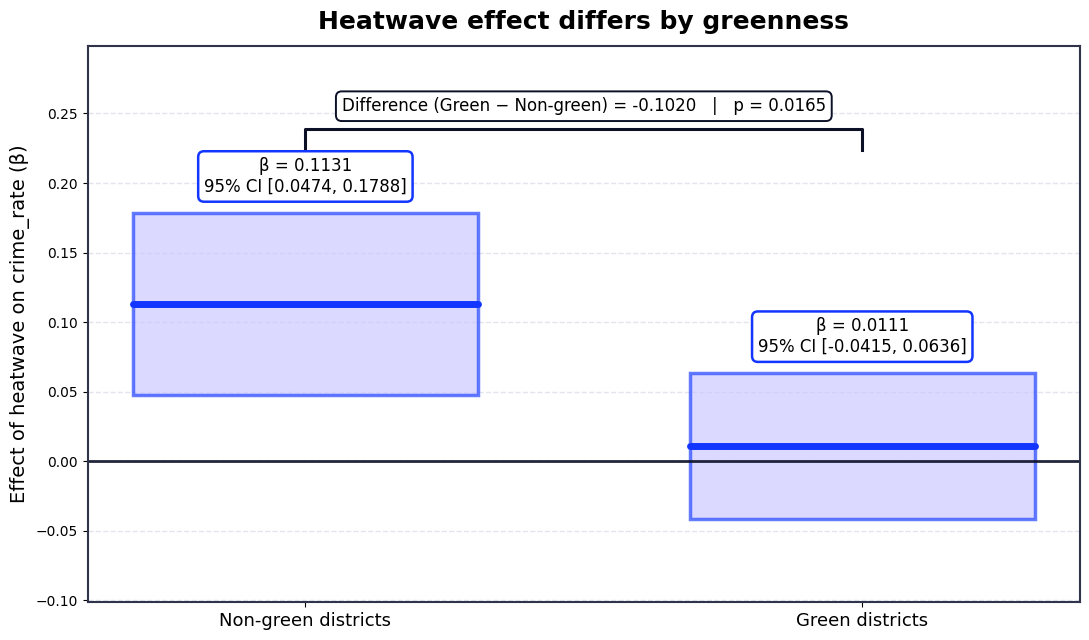

In [ ]:
# Style
BLUE = "#1236FF"      # deep blue
LAV  = "#C9C6FF"      # lavender
DARK = "#0B1026"      # almost-black
GRID = "#D7D9E8"

def get_cov_df_from_res(result):
    """
    Try multiple result attributes to obtain the (robust) covariance matrix as a DataFrame.
    Falls back to diagonal(se^2) if no covariance is exposed.
    """
    candidates = []
    for name in ["cov", "cov_params", "covariance", "_cov"]:
        if hasattr(result, name):
            obj = getattr(result, name)
            mat = obj() if callable(obj) else obj
            if mat is not None:
                candidates.append(mat)

    for mat in candidates:
        # Pandas
        if hasattr(mat, "loc") and hasattr(mat, "columns"):
            try:
                _ = mat.loc[result.params.index, result.params.index]
                return mat
            except Exception:
                pass
        # if not, Numpy
        try:
            arr = np.asarray(mat)
            if arr.ndim == 2 and arr.shape[0] == arr.shape[1] == len(result.params):
                return pd.DataFrame(arr, index=result.params.index, columns=result.params.index)
        except Exception:
            pass

    # Fallback: diagonal from std errors (covariances = 0)
    se = np.asarray(result.std_errors)
    diag = np.diag(se**2)
    return pd.DataFrame(diag, index=result.params.index, columns=result.params.index)


# Pull estimates from `res`
HEAT  = "heatwave_30_3d"
INTER = "heatwave_green"

b1   = float(res.params[HEAT])      # Non-green beta
bi   = float(res.params[INTER])     # Difference (Green - Non-green)
se1  = float(res.std_errors[HEAT])
sei  = float(res.std_errors[INTER])
pval_diff = float(res.pvalues[INTER])

cov_df = get_cov_df_from_res(res)
cov_b1_bi = float(cov_df.loc[HEAT, INTER])

# Betas and 95% CIs
beta_ng = b1
lo_ng   = beta_ng - 1.96 * se1
hi_ng   = beta_ng + 1.96 * se1

beta_g  = b1 + bi
var_g   = se1**2 + sei**2 + 2 * cov_b1_bi
se_g    = float(np.sqrt(max(var_g, 0)))   # guard against tiny negative due to rounding
lo_g    = beta_g - 1.96 * se_g
hi_g    = beta_g + 1.96 * se_g



# Plotting
labels = ["Non-green districts", "Green districts"]
xpos   = [0, 1]
width  = 0.62

fig, ax = plt.subplots(figsize=(11, 6.5))

# CI boxes + coefficient lines
vals = [(beta_ng, lo_ng, hi_ng), (beta_g, lo_g, hi_g)]
for x, (b, lo, hi) in zip(xpos, vals):
    rect = patches.Rectangle(
        (x - width/2, lo),
        width,
        hi - lo,
        linewidth=2.5,
        edgecolor=BLUE,
        facecolor=LAV,
        alpha=0.65
    )
    ax.add_patch(rect)
    ax.plot([x - width/2, x + width/2], [b, b], color=BLUE, linewidth=5, solid_capstyle="round")

# Zero line
ax.axhline(0, color=DARK, linewidth=2, alpha=0.9)

# Grid + axes cosmetics
ax.yaxis.grid(True, linestyle="--", linewidth=1, alpha=0.7, color=GRID)
ax.set_axisbelow(True)

ax.set_xticks(xpos)
ax.set_xticklabels(labels, fontsize=13)
ax.set_ylabel("Effect of heatwave on crime_rate (β)", fontsize=14)
ax.set_title("Heatwave effect differs by greenness", fontsize=18, fontweight="bold", pad=12)

# Callouts (lower than bracket so they never overlap)
def add_callout(x, b, lo, hi, y_offset):
    txt = f"β = {b:.4f}\n95% CI [{lo:.4f}, {hi:.4f}]"
    ax.annotate(
        txt,
        xy=(x, hi),
        xytext=(x, hi + y_offset),
        ha="center",
        va="bottom",
        fontsize=12,
        bbox=dict(boxstyle="round,pad=0.35", fc="white", ec=BLUE, lw=1.8)
    )

add_callout(0, beta_ng, lo_ng, hi_ng, y_offset=0.012)
add_callout(1, beta_g,  lo_g,  hi_g,  y_offset=0.012)

# Difference bracket (higher than callouts)
top_ci = max(hi_ng, hi_g)
br_y0  = top_ci + 0.045
br_y1  = top_ci + 0.060

ax.plot([0, 0, 1, 1], [br_y0, br_y1, br_y1, br_y0], color=DARK, linewidth=2.2)

ax.text(
    0.5,
    br_y1 + 0.010,
    f"Difference (Green − Non-green) = {bi:.4f}   |   p = {pval_diff:.4f}",
    ha="center",
    va="bottom",
    fontsize=12,
    bbox=dict(boxstyle="round,pad=0.35", fc="white", ec=DARK, lw=1.4)
)

# Limits (extra headroom so nothing clips)
ymin = min(lo_ng, lo_g) - 0.06
ymax = br_y1 + 0.06
ax.set_ylim(ymin, ymax)

# Spines
for s in ["top", "right", "left", "bottom"]:
    ax.spines[s].set_color("#30344A")
    ax.spines[s].set_linewidth(1.5)

plt.tight_layout()
plt.savefig("heatwave_greenness_ci.png", dpi=300, bbox_inches="tight")
plt.show()


##Why Greenness Matters

This protection operates through multiple pathways:

- Physical cooling. Trees provide shade and release moisture through evapotranspiration, lowering ambient temperatures. A heatwave in a tree-lined neighborhood isn't as oppressive as the same temperatures in a concrete desert.

- Psychological escape. Parks offer refuge from confined, tense indoor environments. Green neighborhoods provide alternative spaces that concrete districts lack.

- Community resources. Access to nature reduces domestic friction by offering activities and social spaces outside the home.

##Policy Implications:

This finding reveals a troubling inequality: the neighborhoods most vulnerable to heat violence have the least natural protection. Low-vegetation districts—often lower-income communities with decades of underinvestment—bear the full brunt of climate-related violence spikes, while wealthier areas with mature tree canopies remain insulated.

Strategic investments in urban forestry, particularly in underserved neighborhoods, could:

- Reduce domestic violence during extreme heat events
- Address environmental justice by equalizing climate adaptation resources
- Build community resilience as heat waves become more frequent and severe

Two families experiencing the same 35°C heatwave face radically different risks depending on whether they live under trees or under asphalt. As climate change intensifies, this gap will widen unless we invest in greening the communities that need it most. The evidence suggests that planting trees and creating parks in concrete-heavy districts isn't just about beautification—it's a concrete strategy for reducing heat-related violence.

#Endogeneity Assessment: Threats to Causal Inference

##**Non-Classical Measurement Error**

**Heatwave Variable:**
Our heatwave indicator (3 consecutive days ≥30°C) is measured from weather station data, which is generally reliable but subject to:

- Spatial aggregation error: Weather stations may not capture hyperlocal temperature variations within districts. Urban heat islands, microclimates, and elevation differences mean the "true" temperature experienced by residents may differ from station readings.

- Threshold sensitivity: Our 30°C cutoff is somewhat arbitrary. The biological and psychological stress of heat is continuous, not binary. Misclassifying 29.8°C as "no heatwave" introduces measurement error that could attenuate our estimates (bias toward zero).

**Crime Rate:**
Domestic violence reporting is notoriously underreported. LAPD data captures only incidents that were:

- Reported to police (many victims don't call)

- Recorded as domestic violence (classification can vary)

- Occurred in the district where reported (some incidents may be misattributed geographically)

**Implication:**
If measurement error in crime rates or heatwave exposure is random, it biases coefficients toward zero (attenuation bias), meaning our findings are likely conservative. However, if measurement error correlates with treatment—for instance, if heatwaves reduce reporting rates due to decreased mobility or overwhelmed emergency services—this could bias results unpredictably. The consistency of our results across specifications suggests systematic reporting bias is unlikely to drive our findings.

##**Omitted Variable Bias**
Despite our comprehensive fixed effects specification, several confounders could remain:

Potentially Omitted Variables:

1) Time-Varying District Characteristics:

- Economic shocks: Unemployment spikes, business closures, or gentrification could affect both stress levels and violence

- Policing intensity: Changes in police presence or enforcement priorities could alter reporting rates

- Population changes: Migration or demographic shifts within districts over time


2) Other Weather Conditions:

- Air quality: Heat often correlates with poor air quality (ozone, particulates), which independently affects mood and aggression

- Sunlight/daylight hours: Longer days in summer could increase opportunities for violence

- Barometric pressure: Some research links pressure changes to mood and behavior

We control for precipitation and humidity, but air quality and sunlight remain unmeasured. However, these likely operate through heat (hot days = bad air quality), making them mediators rather than confounders.




#Heterogeneity and the Limits of What We Can Claim

We've documented a striking pattern: heatwaves increase domestic violence by 11.3% in concrete-heavy districts but only 1.1% in green districts—a tenfold difference. This appears to offer a clear policy prescription: plant trees to protect communities.

But we need to be careful. What if we're wrong about what's actually protecting those green neighborhoods?

Greenness doesn't randomly distribute across Los Angeles. Districts with tree-lined streets are also wealthier (more A/C, larger homes), less dense (space reduces friction), and have lower baseline stress. Our district fixed effects control for time-invariant differences, but they don't tell us why the heat effect differs. Is it the trees, or everything else that comes with living in a neighborhood wealthy enough to have trees?

To truly isolate vegetation's role, we'd need within-district greening over time, socioeconomic controls (income, A/C penetration, housing density), or randomized interventions. We have none of these.

**We can say with confidence:**
- Heat increases violence; the effect varies dramatically by neighborhood; environmental context matters.

**We cannot say with confidence:**
- Whether vegetation itself is protective or merely a proxy for wealth; whether greening alone would reduce vulnerability.

**For other cities:**

- The heat-violence relationship will likely hold—it's universal. But the magnitude depends on local conditions we can't fully specify. Rather than claiming vegetation as a policy lever, we acknowledge: something about neighborhoods with trees makes them resilient. That might be the trees, the air conditioning, the space, or most likely, all of these as a bundle. Comprehensive interventions—green infrastructure plus cooling centers plus housing improvements—are likely needed, not trees alone.

#Key Findings

This analysis reveals how climate change operates not just through visible disasters but through the quieter violence unfolding inside homes when temperatures rise.

**Heat causes domestic violence**
- When we properly account for district characteristics and temporal patterns, heatwaves increase domestic violence by 4.4%. This effect emerges only when we compare the same neighborhood to itself across different weather conditions—simple geographic comparisons mislead because hot and cool areas differ fundamentally.

**The burden falls unequally**
- The heat effect is ten times stronger in concrete-heavy neighborhoods (11.3%) than in green areas (1.1%). Whether this stems from vegetation itself or correlated advantages remains unclear, but the disparity is stark.

**Violence follows strong temporal rhythms**
- Sundays see 37% more violence, Saturdays 22% more, holidays 28% more. Summer months sustain elevated rates. These patterns dwarf the heat effect in magnitude, but heat adds independent pressure. Critically, heat and temporal patterns operate additively, not synergistically.

#Limitations and Future Directions

**Measurement uncertainty:**

Domestic violence is underreported; if heat affects reporting rates, our estimates could be biased. Temperature stations may miss hyperlocal variation, introducing measurement error that likely makes our estimates conservative.

**Mechanism ambiguity:**
We've shown heat increases violence but can't fully isolate why—physiological stress, routine disruption, or direct aggression effects? Similarly, we observe green neighborhoods show smaller effects but can't separate vegetation's cooling from correlated wealth advantages.

**Generalizability:**
Our Los Angeles findings should replicate qualitatively (heat-aggression is biological) but magnitudes may differ elsewhere. Cities with different climates, housing stock, or vegetation will experience different effect sizes.

**Time horizon:**
Four years reveals effects but not adaptation. Do people acclimate? Do communities develop coping mechanisms? A longer panel would tell us whether these effects persist or fade as populations adjust.

**Confounding:**
We lack time-varying socioeconomic measures—unemployment, evictions, policing changes—that could correlate with heat. We also assume no spillovers between districts (SUTVA), though citywide heatwaves may create spillover effects we're not capturing.

**What's needed next:**
Richer mechanism data (hospital admissions, police response times), socioeconomic controls to separate vegetation from wealth, longer time series to observe adaptation, cross-city replication to establish how effects vary by context, and natural experiments in greening to establish causal protective effects.

#**Appendix**

# Appendix 0: Description of variables and data sources

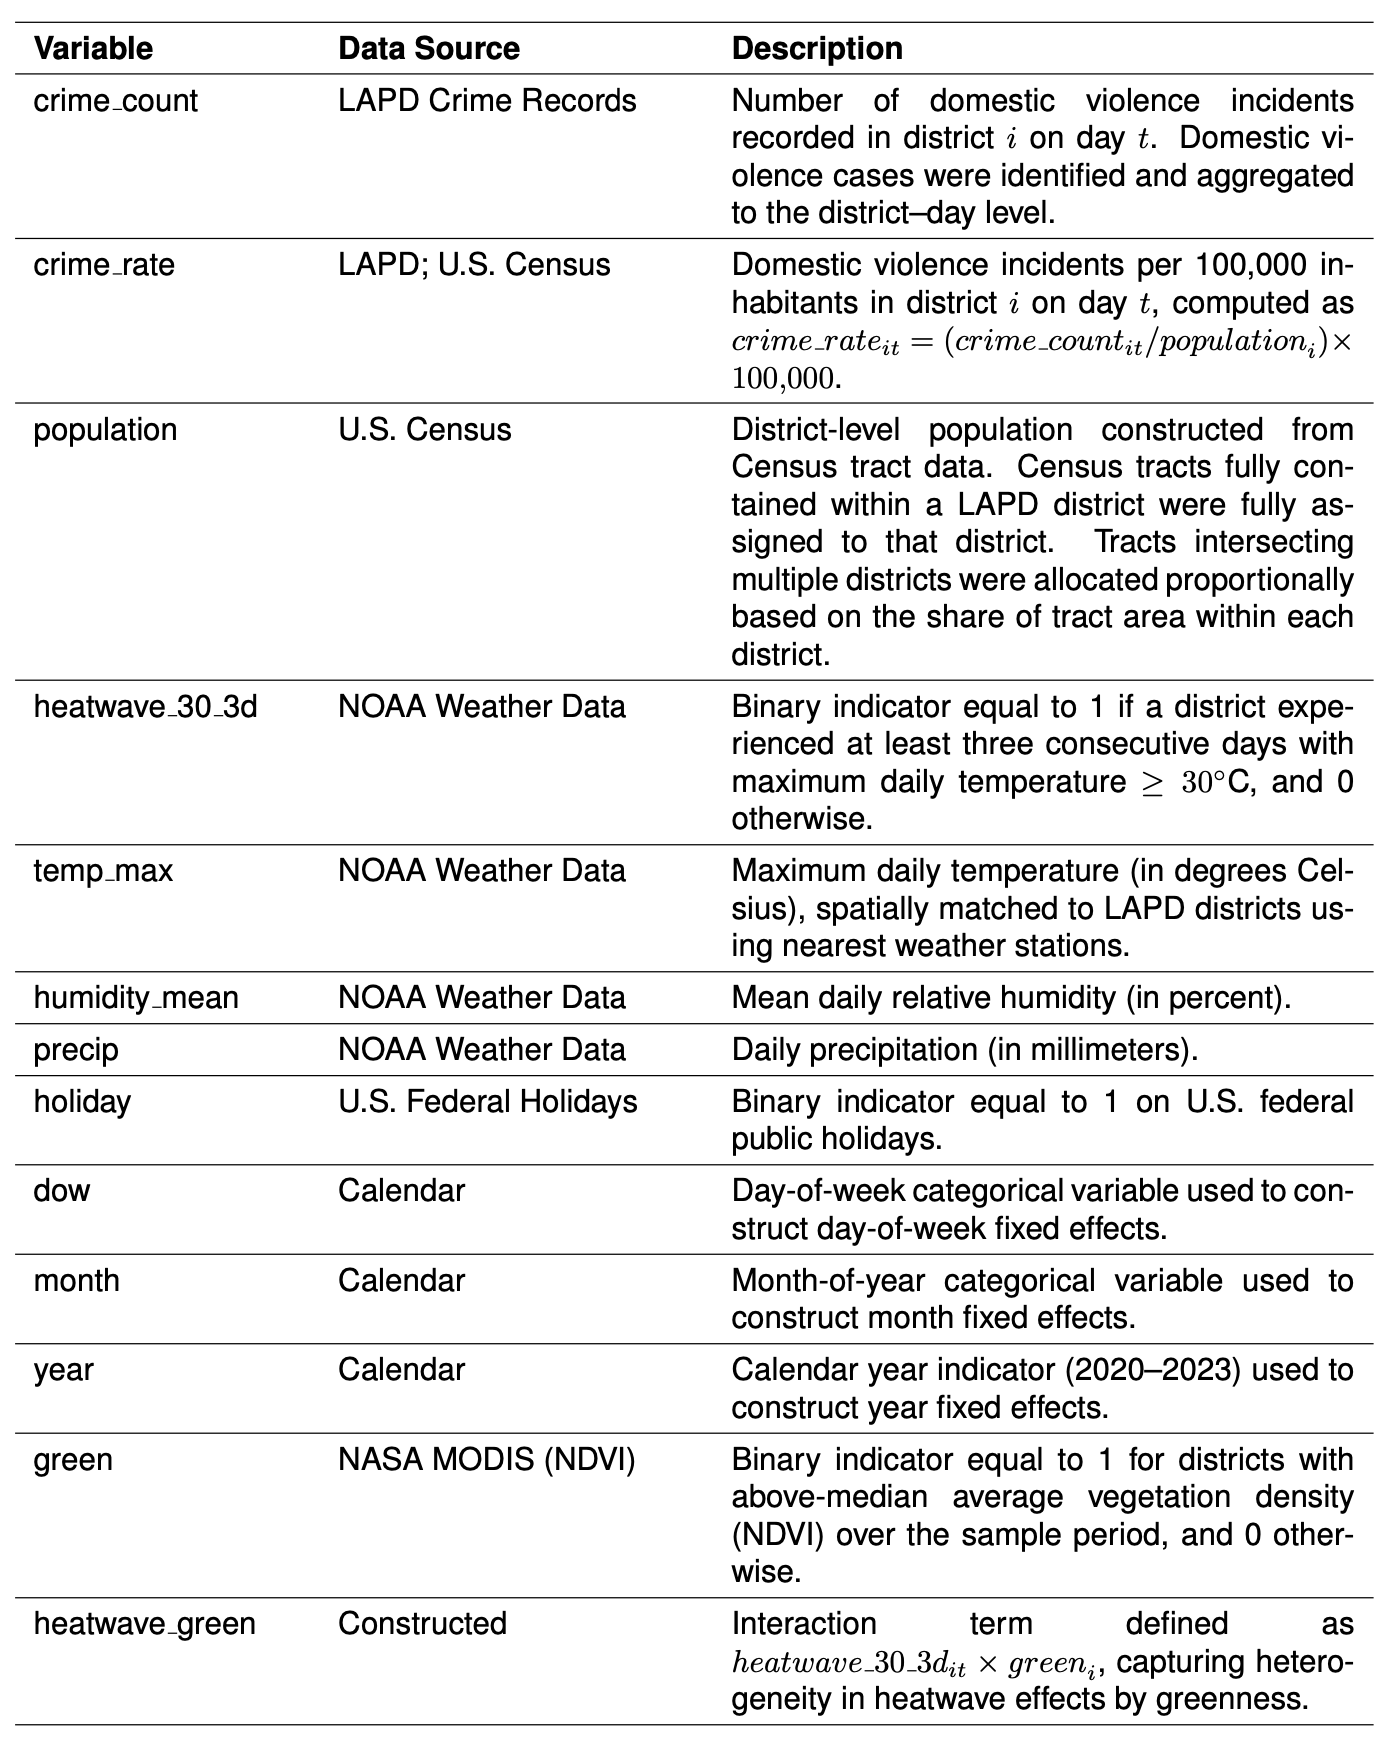

## Appendix 1: OLS Table

In [ ]:
import pandas as pd
from linearmodels.panel import PanelOLS
import statsmodels.api as sm

df['date'] = pd.to_datetime(df['date'])

# Model 1: Simple OLS
X1 = sm.add_constant(df[['heatwave_30_3d']])
y1 = df['crime_rate']
res1 = sm.OLS(y1, X1).fit()

# Model 2: Panel OLS with FE and controls
panel = df.set_index(["district_id", "date"])
y2 = panel["crime_rate"]
X2 = panel[["heatwave_30_3d", "precip", "humidity_mean", "holiday"]].copy()
X2 = X2.join(pd.get_dummies(panel["dow"], prefix="dow", drop_first=True))
X2 = X2.join(pd.get_dummies(panel["month"], prefix="m", drop_first=True))
X2 = X2.join(pd.get_dummies(panel["year"], prefix="y", drop_first=True))
res2 = PanelOLS(y2, X2, entity_effects=True).fit(cov_type="clustered", cluster_entity=True)

# Model 3: Panel OLS with greenness
df['heatwave_green'] = df['heatwave_30_3d'] * df['green']
panel = df.set_index(["district_id", "date"])
y3 = panel["crime_rate"]
X3 = panel[["heatwave_30_3d", "heatwave_green", "precip", "humidity_mean", "holiday"]].copy()
X3 = X3.join(pd.get_dummies(panel["dow"], prefix="dow", drop_first=True))
X3 = X3.join(pd.get_dummies(panel["month"], prefix="m", drop_first=True))
X3 = X3.join(pd.get_dummies(panel["year"], prefix="y", drop_first=True))
res3 = PanelOLS(y3, X3, entity_effects=True).fit(cov_type="clustered", cluster_entity=True)

# Helper function
def get_stars(pval):
    if pval < 0.001: return '***'
    if pval < 0.01: return '**'
    if pval < 0.05: return '*'
    return ''

# Build table
print("\n" + "="*80)
print("Dependent Variable: Domestic Violence Rate")
print("="*80)
print(f"{'Variable':<25} {'(1)':<20} {'(2)':<20} {'(3)':<20}")
print(f"{'':25} {'Simple OLS':<20} {'FE + Controls':<20} {'With Greenness':<20}")
print("-"*80)

# Intercept
print(f"{'Intercept':<25} {res1.params['const']:.4f}{get_stars(res1.pvalues['const']):<16} {'—':<20} {'—':<20}")
print(f"{'':25} ({res1.bse['const']:.4f}){'':<11}")

# Heatwave
hw1 = f"{res1.params['heatwave_30_3d']:.4f}{get_stars(res1.pvalues['heatwave_30_3d'])}"
hw2 = f"{res2.params['heatwave_30_3d']:.4f}{get_stars(res2.pvalues['heatwave_30_3d'])}"
hw3 = f"{res3.params['heatwave_30_3d']:.4f}{get_stars(res3.pvalues['heatwave_30_3d'])}"
print(f"{'Heatwave (30°C, 3d)':<25} {hw1:<20} {hw2:<20} {hw3:<20}")
print(f"{'':25} ({res1.bse['heatwave_30_3d']:.4f}){'':<11} ({res2.std_errors['heatwave_30_3d']:.4f}){'':<11} ({res3.std_errors['heatwave_30_3d']:.4f})")

# Precipitation
pr2 = f"{res2.params['precip']:.4f}{get_stars(res2.pvalues['precip'])}"
pr3 = f"{res3.params['precip']:.4f}{get_stars(res3.pvalues['precip'])}"
print(f"{'Precipitation':<25} {'—':<20} {pr2:<20} {pr3:<20}")
print(f"{'':25} {'':20} ({res2.std_errors['precip']:.4f}){'':<11} ({res3.std_errors['precip']:.4f})")

# Humidity
hm2 = f"{res2.params['humidity_mean']:.4f}{get_stars(res2.pvalues['humidity_mean'])}"
hm3 = f"{res3.params['humidity_mean']:.4f}{get_stars(res3.pvalues['humidity_mean'])}"
print(f"{'Humidity':<25} {'—':<20} {hm2:<20} {hm3:<20}")
print(f"{'':25} {'':20} ({res2.std_errors['humidity_mean']:.4f}){'':<11} ({res3.std_errors['humidity_mean']:.4f})")

# Heatwave × Green (moved to end)
print(f"{'Heatwave × Green':<25} {'—':<20} {'—':<20} {res3.params['heatwave_green']:.4f}{get_stars(res3.pvalues['heatwave_green']):<16}")
print(f"{'':25} {'':20} {'':20} ({res3.std_errors['heatwave_green']:.4f})")

print("-"*80)
print(f"{'Observations':<25} {int(res1.nobs):<20,} {int(res2.nobs):<20,} {int(res3.nobs):<20,}")
print(f"{'R²':<25} {res1.rsquared:<20.3f} {res2.rsquared_within:<20.3f} {res3.rsquared_within:<20.3f}")
print(f"{'District FE':<25} {'No':<20} {'Yes':<20} {'Yes':<20}")
print(f"{'Time FE':<25} {'No':<20} {'Yes':<20} {'Yes':<20}")
print("="*80)
print("Note: Standard errors in parentheses. * p<0.05, ** p<0.01, *** p<0.001")
print("Models (2) and (3): Standard errors clustered at district level")


Dependent Variable: Domestic Violence Rate
Variable                  (1)                  (2)                  (3)                 
                          Simple OLS           FE + Controls        With Greenness      
--------------------------------------------------------------------------------
Intercept                 1.3170***              —                    —                   
                          (0.0071)           
Heatwave (30°C, 3d)       -0.0221              0.0444*              0.1131***           
                          (0.0194)            (0.0213)            (0.0335)
Precipitation             —                    -0.0008              -0.0008             
                                               (0.0006)            (0.0006)
Humidity                  —                    -0.0005              -0.0005             
                                               (0.0004)            (0.0004)
Heatwave × Green          —                    —                  

##Appendix 2: Correlation Matrix

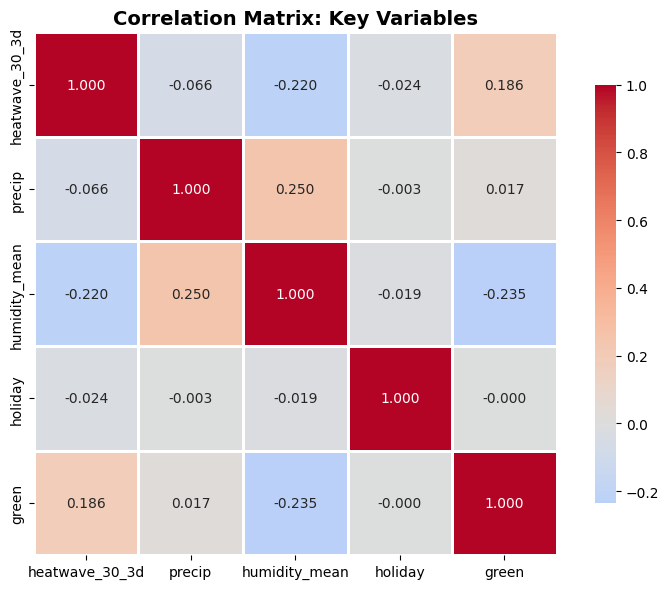


Variance Inflation Factor (VIF) Test
         Variable       VIF
0  heatwave_30_3d  1.180248
1          precip  1.080406
2   humidity_mean  1.705123
3         holiday  1.032686
4           green  1.707802

Interpretation:
VIF < 5: No multicollinearity concern
VIF 5-10: Moderate multicollinearity
VIF > 10: High multicollinearity (problematic)


In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Select variables to check for multicollinearity
vars_to_check = ['heatwave_30_3d', 'precip', 'humidity_mean', 'holiday', 'green']

# Calculate correlation matrix
corr_matrix = df[vars_to_check].corr()

# Create heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm',
            center=0, square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Correlation Matrix: Key Variables', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('correlation_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

# Calculate VIF
print("\n" + "="*50)
print("Variance Inflation Factor (VIF) Test")
print("="*50)

# Prepare data for VIF (drop missing values)
vif_data = df[vars_to_check].dropna()

# Calculate VIF for each variable
vif_results = pd.DataFrame()
vif_results["Variable"] = vars_to_check
vif_results["VIF"] = [variance_inflation_factor(vif_data.values, i) for i in range(len(vars_to_check))]

print(vif_results)
print("\nInterpretation:")
print("VIF < 5: No multicollinearity concern")
print("VIF 5-10: Moderate multicollinearity")
print("VIF > 10: High multicollinearity (problematic)")

To ensure our regression estimates are reliable, we tested for multicollinearity among our key independent variables using both correlation analysis and Variance Inflation Factor (VIF) tests.

The correlation matrix reveals no concerning relationships. The strongest correlation is between humidity and precipitation (0.250), which is expected given their meteorological connection, but far below problematic thresholds. Notably, heatwaves show a modest positive correlation with green districts (0.186), reflecting the geographic reality that inland Valley neighborhoods experience both more heat and more vegetation—precisely why our interaction term is necessary to disentangle district characteristics from heat effects.

The VIF test confirms the absence of multicollinearity issues. All variables show VIF values well below 5 (ranging from 1.03 to 1.71), indicating that each predictor contributes independent information to the model. The highest VIF values are for humidity (1.71) and green (1.71)—both comfortably in the safe range. The rule is that a VIF greater than 5 suggests it is better to drop the variable of the regression, which was not the case here.

#References

Black, M. C., Basile, K. C., Breiding, M. J., Smith, S. G., Walters, M. L., Merrick, M. T., Chen, J., & Stevens, M. R. (2011). The National Intimate Partner and Sexual Violence Survey (NISVS): 2010 Summary Report. National Center for Injury Prevention and Control, Centers for Disease Control and Prevention. https://www.cdc.gov/violenceprevention/pdf/nisvs_report2010-a.pdf

Peterson, C., Kearns, M. C., McIntosh, W. L., Estefan, L. F., Nicolaidis, C., McCollister, K. E., Gordon, A., & Florence, C. (2018). Lifetime economic burden of intimate partner violence among U.S. adults. American Journal of Preventive Medicine, 55(4), 433–444.
https://doi.org/10.1016/j.amepre.2018.04.049

Britannica. (2025). Los Angeles wildfires of 2025. Encyclopædia Britannica. https://www.britannica.com/event/Los-Angeles-wildfires-of-2025

City of Los Angeles. (2024). Domestic Violence Calls from 2020 to Present [Dataset]. Los Angeles Open Data. https://data.lacity.org/Public-Safety/Domestic-Violence-Calls-from-2020-to-Present/qq59-f26t/about_data

KTLA. (2024, December). LA sees second driest period in history, data shows. KTLA 5. https://ktla.com/news/local-news/la-nina-los-angeles-sees-second-driest-period-in-history-data-shows/

NASA. (2025, January). Temperatures rising: NASA confirms 2024 warmest year on record. NASA News. https://www.nasa.gov/news-release/temperatures-rising-nasa-confirms-2024-warmest-year-on-record/

NBC News. (2025, January). California wildfires: What we know about the Palisades and Eaton fires. NBC News. https://www.nbcnews.com/news/us-news/california-wildfires-what-we-know-palisades-eaton-los-angeles-rcna188239

NOAA. (2025, January). 2024 was the world's warmest year on record. National Oceanic and Atmospheric Administration. https://www.noaa.gov/news/2024-was-worlds-warmest-year-on-record

U.S. Census Bureau. (2024). Population estimates for Los Angeles city, California. United States Census Bureau. https://www.census.gov/quickfacts/losangelescitycalifornia

Anderson, C. A. (1989). Temperature and aggression: Ubiquitous effects of heat on occurrence of human violence. Psychological Bulletin, 106(1), 74–96. https://doi.org/10.1037/0033-2909.106.1.74

Anderson, C. A. (2001). Heat and violence. Current Directions in Psychological Science, 10(1), 33–38. https://doi.org/10.1111/1467-8721.00109

Anderson, C. A., Anderson, K. B., Dorr, N., DeNeve, K. M., & Flanagan, M. (2000). Temperature and aggression. In M. P. Zanna (Ed.), Advances in experimental social psychology (Vol. 32, pp. 63–133). Academic Press. https://doi.org/10.1016/S0065-2601(00)80004-0

Hsiang, S. M., Burke, M., & Miguel, E. (2013). Quantifying the influence of climate on human conflict. Science, 341(6151), 1235367. https://doi.org/10.1126/science.1235367